Board Report Storyboard

**Audience:** Non-technical members of the Duka Electronics Board of Directors reviewing H1 2026 results on mobile screens before next week's board meeting.
* **Decision:** Where to focus H2 2026 marketing budget, inventory allocation, and digital channel investments to sustain momentum and lift second-half revenue.
* **Big Idea:** Core compute hardware (**Laptops** and **Tablets**, **84.8%** of revenue) and **Nairobi In-Store** carried H1 to **KES 71.8M**; H2 growth depends on scaling **Online** promotions in Nairobi and Mombasa while bundling high-margin accessories at hardware checkout. 

SCR Narrative Framework

**Situation:** In H1 2026 (January–June), Duka Electronics generated **KES 71,792,500** across **1,000 completed orders** (average order value **KES 71,792**) spanning five Kenyan branches and three sales channels.
* **Complication:** Revenue is heavily concentrated and lost momentum late in the half—**Nairobi** alone drives **36.4%** (**KES 26.1M**), **Laptops and Tablets** account for **84.8%** (**KES 60.9M**), and monthly sales declined **19.3%** from April's peak (**KES 13.5M**) to June (**KES 10.9M**).
* **Resolution:** Focus H2 execution on three levers: (1) scale targeted **Online** campaigns in Nairobi and Mombasa, where **83 Premium online orders** already generated **KES 10.2M**; (2) introduce checkout bundles pairing accessories (**Phones, Headphones, Chargers**) with Laptop/Tablet purchases; and (3) launch Q3 promotional drives across regional branches (**Mombasa, Nakuru, Kisumu, Eldoret**) to reverse June's slowdown.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)
os.makedirs("reports", exist_ok=True)

# Load dataset & engineer required columns
duka = pd.read_csv("duka_sales.csv", parse_dates=["order_date"])
duka["revenue"] = duka["quantity"] * duka["unit_price"]
duka["month_num"] = duka["order_date"].dt.month
duka["month_short"] = duka["order_date"].dt.strftime("%b")
duka["month_name"] = duka["order_date"].dt.month_name()

# --- Dynamic KPI & Insight-Title Calculations ---
total_rev = duka["revenue"].sum()
total_orders = len(duka)
aov = duka["revenue"].mean()

branch_rev = duka.groupby("branch")["revenue"].sum().sort_values(ascending=True)
top_branch = branch_rev.index[-1]
top_branch_rev = branch_rev.iloc[-1]
top_branch_share = top_branch_rev / total_rev * 100
runner_up_branch = branch_rev.index[-2]

monthly_rev = (
    duka.groupby(["month_num", "month_short", "month_name"], as_index=False)["revenue"]
    .sum()
    .sort_values("month_num")
)
peak_row = monthly_rev.loc[monthly_rev["revenue"].idxmax()]
trough_row = monthly_rev.loc[monthly_rev["revenue"].idxmin()]
peak_to_trough_drop = (peak_row["revenue"] - trough_row["revenue"]) / peak_row["revenue"] * 100
peak_vs_trough_lift = (peak_row["revenue"] - trough_row["revenue"]) / trough_row["revenue"] * 100

prod_rev = duka.groupby("product")["revenue"].sum().sort_values(ascending=True)
laptop_rev = prod_rev["Laptop"]
tablet_rev = prod_rev["Tablet"]
core_compute_share = (laptop_rev + tablet_rev) / total_rev * 100

chan_rev = duka.groupby("channel")["revenue"].sum().sort_values(ascending=False)
chan_shares = chan_rev / total_rev * 100

prem_coast_cap = duka[
    (duka["unit_price"] >= 28000)
    & (duka["channel"] == "Online")
    & (duka["branch"].isin(["Nairobi", "Mombasa"]))
]

In [3]:
fig_b, ax_b = plt.subplots(figsize=(6.5, 4.2), dpi=150)
branch_unsorted = duka.groupby("branch")["revenue"].sum()
colors_rainbow = ["#ff0000", "#00ff00", "#0000ff", "#ffff00", "#ff00ff"]
ax_b.bar(branch_unsorted.index, branch_unsorted.values, color=colors_rainbow, edgecolor="black", hatch="//")
ax_b.set_title("Revenue by Branch", fontsize=12)
ax_b.set_xlabel("Branch Name")
ax_b.set_ylabel("Revenue")
ax_b.tick_params(axis="x", rotation=45)
ax_b.grid(True, linestyle="--", linewidth=1.2, color="gray")
plt.tight_layout()
fig_b.savefig("figures/before.png", dpi=150)
plt.close(fig_b)

In [4]:
after_title = (
    f"{top_branch} drives {top_branch_share:.1f}% of H1 revenue "
    f"(KES {top_branch_rev/1e6:.1f}M) — nearly 2x runner-up {runner_up_branch}"
)
fig_a, ax_a = plt.subplots(figsize=(7.2, 4.2), dpi=200)
bar_colors = ["#B0BEC5" if b != top_branch else "#0F4C81" for b in branch_rev.index]
bars = ax_a.barh(branch_rev.index, branch_rev.values / 1e6, color=bar_colors, height=0.6)
ax_a.set_title(after_title, fontsize=11.5, fontweight="bold", loc="left", pad=12, color="#102A43")
ax_a.set_xlim(0, 31.5)
for spine in ["top", "right", "bottom"]:
    ax_a.spines[spine].set_visible(False)
ax_a.spines["left"].set_color("#BCCCDC")
ax_a.xaxis.set_visible(False)
for bar in bars:
    w = bar.get_width()
    ax_a.text(w + 0.5, bar.get_y() + bar.get_height() / 2, f"KES {w:.1f}M", va="center", fontsize=10, fontweight="bold", color="#102A43")
fig_a.text(0.01, 0.01, f"Source: Duka Electronics H1 2026 Sales Extract (n = {total_orders:,} orders)", fontsize=8, color="#627D98")
plt.tight_layout(rect=[0, 0.04, 1, 1])
fig_a.savefig("figures/after.png", dpi=200)
plt.close(fig_a)

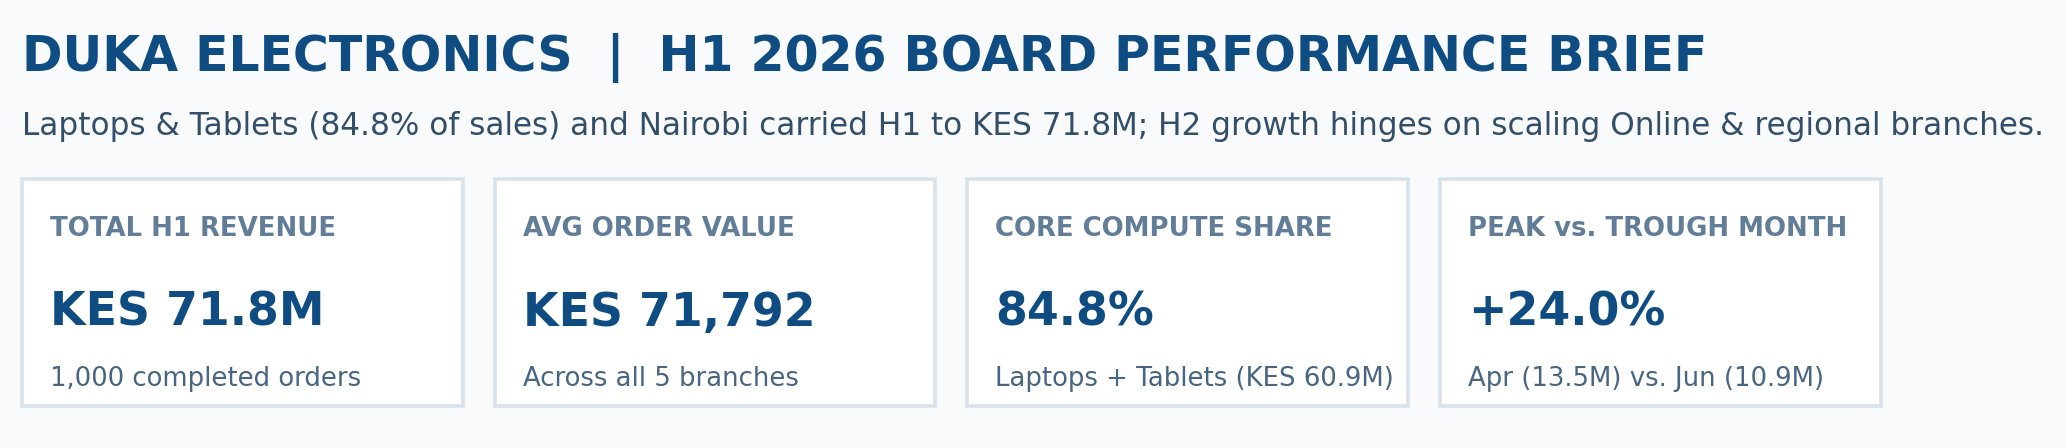

In [5]:
fig = plt.figure(figsize=(11, 13.5), dpi=220, facecolor="#F8FAFC")
gs = fig.add_gridspec(3, 2, height_ratios=[0.78, 1.35, 1.35], hspace=0.40, wspace=0.25)

# Top Banner & 4 KPI Scorecards
ax_top = fig.add_subplot(gs[0, :])
ax_top.axis("off")
ax_top.text(0.0, 0.88, "DUKA ELECTRONICS  |  H1 2026 BOARD PERFORMANCE BRIEF", fontsize=16, fontweight="bold", color="#0F4C81")
ax_top.text(
    0.0, 0.72,
    f"Laptops & Tablets ({core_compute_share:.1f}% of sales) and {top_branch} carried H1 to KES {total_rev/1e6:.1f}M; H2 growth hinges on scaling Online & regional branches.",
    fontsize=10.2, color="#334E68"
)

kpis = [
    ("TOTAL H1 REVENUE", f"KES {total_rev/1e6:.1f}M", f"{total_orders:,} completed orders"),
    ("AVG ORDER VALUE", f"KES {aov:,.0f}", "Across all 5 branches"),
    ("CORE COMPUTE SHARE", f"{core_compute_share:.1f}%", f"Laptops + Tablets (KES {(laptop_rev+tablet_rev)/1e6:.1f}M)"),
    ("PEAK vs. TROUGH MONTH", f"+{peak_vs_trough_lift:.1f}%", f"{peak_row['month_short']} ({peak_row['revenue']/1e6:.1f}M) vs. {trough_row['month_short']} ({trough_row['revenue']/1e6:.1f}M)"),
]
for idx_k, (label, val, sub) in enumerate(kpis):
    x0 = idx_k * 0.252
    rect = plt.Rectangle((x0, 0.05), 0.235, 0.56, transform=ax_top.transAxes, facecolor="white", edgecolor="#D9E2EC", linewidth=1.2, clip_on=False)
    ax_top.add_patch(rect)
    ax_top.text(x0 + 0.015, 0.47, label, transform=ax_top.transAxes, fontsize=8.5, fontweight="bold", color="#627D98")
    ax_top.text(x0 + 0.015, 0.25, val, transform=ax_top.transAxes, fontsize=15, fontweight="bold", color="#0F4C81")
    ax_top.text(x0 + 0.015, 0.10, sub, transform=ax_top.transAxes, fontsize=8.5, color="#486581")

In [6]:
ax1 = fig.add_subplot(gs[1, 0], facecolor="white")
t1 = f"1. Revenue peaked in {peak_row['month_name']} (KES {peak_row['revenue']/1e6:.1f}M) before easing {peak_to_trough_drop:.0f}% by {trough_row['month_name']}"
ax1.plot(monthly_rev["month_short"], monthly_rev["revenue"] / 1e6, marker="o", linewidth=2.8, markersize=8, color="#0F4C81")
ax1.fill_between(monthly_rev["month_short"], monthly_rev["revenue"] / 1e6, 9.5, color="#0F4C81", alpha=0.08)
ax1.set_ylim(9.5, 15.0)
ax1.set_title(t1, fontsize=10.5, fontweight="bold", loc="left", pad=10, color="#102A43")
ax1.set_ylabel("Revenue (KES Millions)", fontsize=9.5, color="#334E68")
for _, r in monthly_rev.iterrows():
    ax1.text(r["month_short"], r["revenue"] / 1e6 + 0.22, f"{r['revenue']/1e6:.1f}M", ha="center", fontsize=9, fontweight="bold", color="#102A43")
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.grid(axis="y", linestyle=":", alpha=0.6)

In [7]:
ax2 = fig.add_subplot(gs[1, 1], facecolor="white")
t2 = f"2. {top_branch} generated {top_branch_share:.1f}% of H1 sales (KES {top_branch_rev/1e6:.1f}M)"
b_cols = ["#9FB3C8" if b != top_branch else "#0F4C81" for b in branch_rev.index]
bars2 = ax2.barh(branch_rev.index, branch_rev.values / 1e6, color=b_cols, height=0.58)
ax2.set_xlim(0, 31.5)
ax2.set_title(t2, fontsize=10.5, fontweight="bold", loc="left", pad=10, color="#102A43")
ax2.set_xlabel("Revenue (KES Millions)", fontsize=9.5, color="#334E68")
for bar in bars2:
    w = bar.get_width()
    ax2.text(w + 0.5, bar.get_y() + bar.get_height() / 2, f"KES {w:.1f}M", va="center", fontsize=9, fontweight="bold", color="#102A43")
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

In [8]:
ax3 = fig.add_subplot(gs[2, 0], facecolor="white")
t3 = f"3. Laptops (KES {laptop_rev/1e6:.1f}M) & Tablets ({tablet_rev/1e6:.1f}M) deliver {core_compute_share:.0f}% of revenue"
p_cols = ["#0F4C81" if p in ("Laptop", "Tablet") else "#BCCCDC" for p in prod_rev.index]
bars3 = ax3.barh(prod_rev.index, prod_rev.values / 1e6, color=p_cols, height=0.58)
ax3.set_xlim(0, 49)
ax3.set_title(t3, fontsize=10.5, fontweight="bold", loc="left", pad=10, color="#102A43")
ax3.set_xlabel("Revenue (KES Millions)", fontsize=9.5, color="#334E68")
for bar in bars3:
    w = bar.get_width()
    ax3.text(w + 0.7, bar.get_y() + bar.get_height() / 2, f"KES {w:.1f}M", va="center", fontsize=9, fontweight="bold", color="#102A43")
ax3.spines["top"].set_visible(False)
ax3.spines["right"].set_visible(False)

In [9]:
ax4 = fig.add_subplot(gs[2, 1], facecolor="white")
t4 = f"4. In-store leads at {chan_shares['In-store']:.1f}%, while Online captures {chan_shares['Online']:.1f}% (KES {chan_rev['Online']/1e6:.1f}M)"
c_cols = ["#0F4C81", "#2B6CB0", "#9FB3C8"]
bars4 = ax4.bar(chan_rev.index, chan_rev.values / 1e6, color=c_cols, width=0.5)
ax4.set_ylim(0, 48)
ax4.set_title(t4, fontsize=10.5, fontweight="bold", loc="left", pad=10, color="#102A43")
ax4.set_ylabel("Revenue (KES Millions)", fontsize=9.5, color="#334E68")
for bar, sh in zip(bars4, chan_shares):
    h = bar.get_height()
    ax4.text(bar.get_x() + bar.get_width() / 2, h + 1.0, f"KES {h:.1f}M\n({sh:.1f}%)", ha="center", fontsize=9, fontweight="bold", color="#102A43")
ax4.spines["top"].set_visible(False)
ax4.spines["right"].set_visible(False)

fig.text(
    0.04, 0.015,
    f"H2 Focus: Bundle accessories with Laptop/Tablet orders & scale Online in Nairobi/Mombasa ({len(prem_coast_cap)} Premium online orders = KES {prem_coast_cap['revenue'].sum()/1e6:.1f}M in H1).  |  Source: duka_sales.csv (n={total_orders:,}).",
    fontsize=8.3, fontweight="bold", color="#334E68"
)
fig.savefig("reports/duka_board_report.png", dpi=220, bbox_inches="tight")
plt.close(fig)